# M07 概覽 | 後端部署總覽：Q/DQ 圖之後

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/bobondemon/pt2e_quantize_and_deploy/blob/main/m07_representation_lowering/00_overview.ipynb)

M01～M06 的終點都是 `convert_pt2e` 產出的 Q/DQ 圖。它標好了「哪裡要量化、用什麼 qparams」，但運算本身仍是 fp32 的 conv、linear，**它不會變快**（M02-3）。
要變快，得有人把圖上的量化運算換成真正的 int8 kernel。M07～M10 回答的就是這件事：誰來換、在哪一步換、換不了的怎麼辦。

這篇概覽分成兩半：

- **前半是 M07～M10 共用的先備知識**：後端分成哪幾層、從 Q/DQ 圖出發有哪幾條路線、為什麼量化之前就要先選後端。
- **後半是 M07 本章**：離開 PyTorch 之前，Q/DQ 圖在 PyTorch 裡還能被怎麼處理（reference representation、lowering、Inductor），以及比較後端結果時的規矩。

In [ ]:
#| include: false
# 在 Google Colab 上執行時：下載本教材的程式並安裝套件（第一次約需幾分鐘）。
# 在自己的電腦上執行時（環境見 README），這一格什麼都不做。
import sys

if "google.colab" in sys.modules:
    import os
    import subprocess

    repo = "/content/pt2e_quantize_and_deploy"
    if not os.path.exists(repo):
        subprocess.run(["git", "clone", "-q", "--depth", "1",
                        "https://github.com/bobondemon/pt2e_quantize_and_deploy.git", repo], check=True)
        subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                        "--extra-index-url", "https://download.pytorch.org/whl/cpu",
                        "torch==2.14.0+cpu", "torchao==0.18.0", "onnx==1.23.0", "onnxscript==0.7.2",
                        "onnxruntime==1.30.0", "tabulate", "graphviz"], check=True)
    sys.path.insert(0, repo)  # 讓 notebook 能 import 本教材的 common/
    os.chdir(f"{repo}/m07_representation_lowering")

In [1]:
#| echo: false
import copy

import torch

from common.data import calibration_batches
from common.models import example_inputs, get_model
from common.pt2e import convert_pt2e, export_module, get_xnnpack_quantizer, prepare_pt2e, quiet
from common.viz import draw

quiet()
_ = torch.manual_seed(0)

## M07～M10 回答的問題

| 問題 | 一句話的答案 | 章節 |
|---|---|---|
| Q/DQ 圖在 PyTorch 裡能變成整數運算嗎？ | 要有對上的 pattern，運算才會變成整數；沒有就保留 fp32 | M07-2 |
| 比較兩種實作的數值前，要先知道什麼？ | fp32 本身換個 kernel 就差 1e-5～1e-4，這是底線 | M07-1 |
| 交給 ExecuTorch + XNNPACK 會怎樣？ | 匯出時就切好子圖、存成 `.pte`，執行時用 XNNPACK 的 int8 kernel | M08 |
| 交給 ONNX Runtime 會怎樣？ | 匯出 QDQ ONNX，ONNX Runtime 建 session 時才把單元換成 int8 op | M09 |
| 硬體限制更多時，Quantizer 要怎麼寫？ | 把硬體約束寫成標籤，再檢查 Q/DQ 圖、把不支援的 op 切回 CPU | M10 |

## 先看一個例子：Q/DQ 圖上的單元

最小的 conv + relu 做完 PTQ（XNNPACKQuantizer，per-channel weight），convert 之後的 Q/DQ 圖：

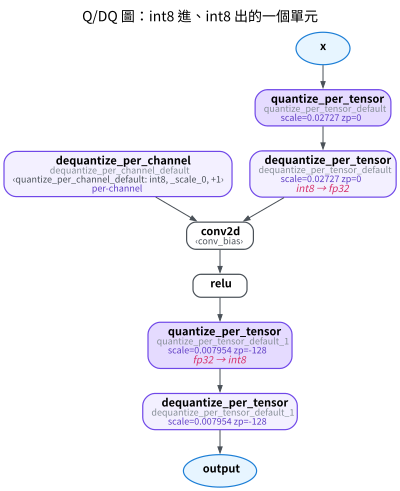

In [2]:
#| echo: false
prepared = prepare_pt2e(export_module(get_model("conv_relu").eval(), example_inputs()), get_xnnpack_quantizer(is_per_channel=True)[0])
with torch.no_grad():
    for batch in calibration_batches(128):
        prepared(*batch)
qdq = convert_pt2e(copy.deepcopy(prepared))
draw(qdq, title="Q/DQ 圖：int8 進、int8 出的一個單元",
     notes={"dequantize_per_tensor_default": "int8 → fp32", "quantize_per_tensor_default_1": "fp32 → int8"})

請看中間這一段：輸入先 `dequantize` 成 fp32，經過 fp32 的 conv2d、relu，再 `quantize` 回 int8。這樣一段「dq → op → q」叫做一個**單元**：

```text
int8 ─ dq ─→ fp32 ─ conv2d、relu ─→ fp32 ─ q ─→ int8
```

weight 那一邊也一樣：int8 常數經過 `dequantize_per_channel` 變回 fp32 才進 conv2d。單元的語意是 int8 進、int8 出，但中間的運算仍是 fp32。要變快，得有人認出這個單元，換成一顆 int8 的 conv-relu kernel。

M08～M10 的每個後端，吃的都是這種由單元組成的 Q/DQ 圖。先看這張圖會交給誰（前半），再看 PyTorch 自己能把單元變成什麼（後半）。

## 從 Q/DQ 圖到硬體：分成三層

ExecuTorch、ONNX Runtime、XNNPACK、oneDNN 常被並列成「後端」，但它們**不在同一層**。從 Q/DQ 圖往下走，一路是：

```text
Q/DQ 圖               PT2E 的終點（M01～M06）
  → 部署檔            .pte／.onnx／OpenVINO IR
  → 推論框架          ExecuTorch／ONNX Runtime／OpenVINO
  → 硬體擴充單位      backend／Execution Provider／device plugin
  → kernel 函式庫     XNNPACK／oneDNN／MLAS…
  → 硬體              CPU／GPU／NPU
```

中間三層的定義：

- **推論框架**（也常叫 runtime）：讀部署檔、決定每一段圖交給誰、管理記憶體、排程執行。它自己不一定會算 conv。
- **硬體擴充單位**：推論框架接上某種硬體或函式庫的插槽。三個框架叫法不同：ExecuTorch 叫 backend（交出去的子圖叫 delegate），ONNX Runtime 叫 Execution Provider（EP），OpenVINO 叫 device plugin。
- **kernel 函式庫**：真正算 conv、matmul 的程式碼。它不讀模型檔，一定要有推論框架呼叫它。

### 推論框架

| | ExecuTorch | ONNX Runtime（ORT） | OpenVINO（OV） |
|---|---|---|---|
| 主導者 | Meta／PyTorch | 微軟 | Intel |
| 部署檔 | `.pte` | `.onnx` | OpenVINO IR（`.xml` 圖 + `.bin` weight） |
| 硬體擴充單位 | backend | Execution Provider | device plugin |
| 何時決定交給誰 | 匯出時，partitioner 先切好 | 建 session 時，依 EP 的順序 | 編譯模型時，依指定的 device |
| 主要目標 | 手機、邊緣裝置 | 跨平台、跨框架 | Intel 的 CPU、GPU、NPU |

「何時決定交給誰」這個 row 最值得記住：它決定 int8 kernel 在哪一步出現，M08、M09 各看一次。

### kernel 函式庫

| kernel 函式庫 | 開發者 | 主要執行目標 | 本專案裡誰呼叫它 |
|---|---|---|---|
| XNNPACK | Google | arm／x86／WebAssembly 的 CPU | ExecuTorch 的 XNNPACK backend（M08） |
| oneDNN（舊名 MKL-DNN） | Intel | 以 x86 CPU 為主 | PyTorch 的 mkldnn、torchao 的 x86 lowering（M07-2） |
| MLAS | 微軟 | CPU | ORT 預設的 CPU EP（M09） |
| NNPACK | 開源專案 | CPU（fp32） | PyTorch eager 的 conv 快速路徑（M07-1） |

arm 上還常見 Arm 自己的 ACL（Arm Compute Library）與 KleidiAI。在 openvino 2026.4.1、macOS arm64 上試過：OpenVINO 的 CPU plugin 用 ACL 算 conv，部分 MatMul 用 KleidiAI。

### 同一個函式庫，可以接在好幾個框架下

硬體擴充單位只是轉接頭，同一個 kernel 函式庫可以接在好幾個框架下面：XNNPACK 是 ExecuTorch 的 backend，也是 ORT 的一個 EP。
不過 EP 能不能用，要看你裝的那個 ORT build 有沒有編進去：pip 的 `onnxruntime`、`onnxruntime-gpu`、自己從原始碼編的 ORT，編進去的 EP 都不同。ORT 提供兩個函式回答這件事：

- `ort.get_all_providers()`：這個版本的 ORT 認得的所有 EP 名稱，和你的機器無關。
- `ort.get_available_providers()`：你裝的這個 build 實際編進去、能用的 EP，依 ORT 預設的優先順序排列。

一個 build 裡有好幾個 EP 時，用哪一個是建 session 時由 `ort.InferenceSession(..., providers=[...])` 指定的，依清單順序優先。
M09 一律指定 `providers=["CPUExecutionProvider"]`，所以不論你的 build 有沒有 XNNPACK EP，M09 看到的 int8 kernel 都是 CPU EP 的 MLAS，和 M08 的 XNNPACK 是兩套不同的實作。

ExecuTorch 那一側，backend 就是 `executorch.backends` 底下的子套件。列出來看（需要 `uv sync --group executorch`）：

In [3]:
import importlib.util
from pathlib import Path

if importlib.util.find_spec("executorch") is None:
    print("沒有安裝 executorch（uv sync --group executorch）")
else:
    import executorch.backends

    root = Path(executorch.backends.__path__[0])
    backends = sorted(p.name for p in root.iterdir()
                      if p.is_dir() and p.name not in {"test", "transforms", "example", "__pycache__"})
    print(f"executorch.backends 底下的 {len(backends)} 個資料夾：")
    print(backends)
    assert "xnnpack" in backends

executorch.backends 底下的 16 個資料夾：
['aoti', 'apple', 'arm', 'cadence', 'cortex_m', 'cuda', 'mediatek', 'mlx', 'native', 'nxp', 'openvino', 'qualcomm', 'samsung', 'vulkan', 'webgpu', 'xnnpack']


每個資料夾是一個（或一組）backend：`xnnpack` 是 M08 用的 CPU backend，`apple` 底下有 Core ML，`qualcomm` 是 QNN，`openvino` 是 OpenVINO……XNNPACK 只是其中一個。

### 轉接頭背後，不一定是 kernel 函式庫

有幾個名字同時是 ExecuTorch 的 backend 與 ORT 的 EP：OpenVINO、Core ML、QNN。它們本身是另一套推論框架或 runtime，交給它們的子圖會被**再分派一次**：

| 名字 | 是什麼 | 接在哪裡 | 交出去之後 |
|---|---|---|---|
| XNNPACK | kernel 函式庫 | ExecuTorch 的 backend；ORT 的 EP | 直接執行 CPU kernel |
| OpenVINO | Intel 的推論框架 | ExecuTorch 的 backend；ORT 的 EP | OpenVINO 再選 device plugin 與 kernel |
| Core ML | Apple 的推論框架 | ExecuTorch 的 backend；ORT 的 EP | Core ML 再選 CPU、GPU 或 Neural Engine |
| QNN | Qualcomm 的 runtime | ExecuTorch 的 backend；ORT 的 EP | QNN 再選 Qualcomm 的運算單元 |

## 誰呼叫誰

把推論框架與 kernel 函式庫之間的關係畫在一起（部署檔怎麼來，留到下一節）。淺紅色是推論框架，黃色是 kernel 函式庫。
實線是在本篇寫出的版本裡查得到的關係（套件目錄、EP 名稱、原始碼或試作）；虛線只有文件說法：OpenVINO 在 x86 上用 oneDNN 是文件的說法，沒有在 x86 上試過。

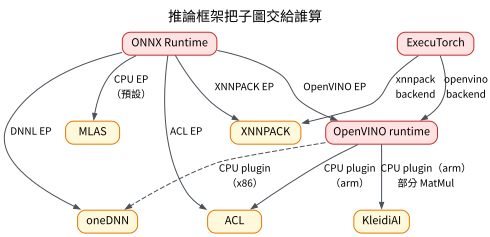

In [4]:
#| echo: false
import graphviz
from IPython.display import display

from common.viz import FONT

KIND = {"src": ("#E7F5FF", "#1C7ED6"), "fmt": ("#EBFBEE", "#2B8A3E"),
        "fw": ("#FFE3E3", "#C92A2A"), "lib": ("#FFF9DB", "#E67700")}


def flow(nodes, edges, title):
    """nodes: (id, 標籤, 種類)；edges: (起點, 終點, 邊的說明, 是否虛線)。"""
    g = graphviz.Digraph(format="svg")
    g.attr(rankdir="TB", bgcolor="white", fontname=FONT, nodesep="0.35", ranksep="0.5",
           label=title, labelloc="t", fontsize="14")
    g.attr("node", fontname=FONT, fontsize="11", shape="box", style="filled,rounded", margin="0.12,0.05", height="0.3")
    g.attr("edge", fontname=FONT, fontsize="10", color="#495057", arrowsize="0.6")
    for name, label, kind in nodes:
        fill, line = KIND[kind]
        g.node(name, label, fillcolor=fill, color=line)
    for a, b, label, dashed in edges:
        g.edge(a, b, label=label, style="dashed" if dashed else "solid")
    display(g)


flow(
    [("ET", "ExecuTorch", "fw"), ("ORT", "ONNX Runtime", "fw"), ("OV", "OpenVINO runtime", "fw"),
     ("XNN", "XNNPACK", "lib"), ("MLAS", "MLAS", "lib"), ("DNNL", "oneDNN", "lib"),
     ("ACL", "ACL", "lib"), ("KAI", "KleidiAI", "lib")],
    [("ET", "XNN", "xnnpack\nbackend", False), ("ET", "OV", "openvino\nbackend", False),
     ("ORT", "MLAS", "CPU EP\n（預設）", False), ("ORT", "XNN", "XNNPACK EP", False),
     ("ORT", "DNNL", "DNNL EP", False), ("ORT", "OV", "OpenVINO EP", False), ("ORT", "ACL", "ACL EP", False),
     ("OV", "DNNL", "CPU plugin\n（x86）", True), ("OV", "ACL", "CPU plugin\n（arm）", False),
     ("OV", "KAI", "CPU plugin（arm）\n部分 MatMul", False)],
    "推論框架把子圖交給誰算",
)

## 三條路線：從 Q/DQ 圖出發

PT2E 不會直接產生這三種部署檔。Q/DQ 圖要經過各框架自己的橋接步驟，才變成框架讀得懂的檔案。藍色是 Q/DQ 圖，綠色是部署檔或模型 IR，淺紅色是推論框架；虛線只試過 fp32 模型（ONNX → `ov.Model`）：

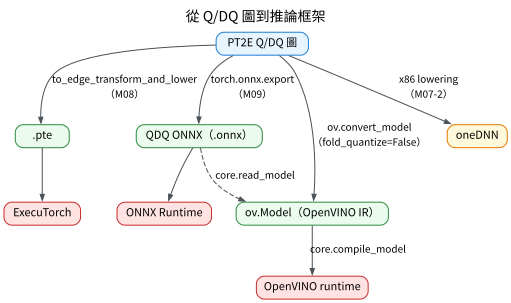

In [5]:
#| echo: false
flow(
    [("QDQ", "PT2E Q/DQ 圖", "src"),
     ("PTE", ".pte", "fmt"), ("ONNX", "QDQ ONNX（.onnx）", "fmt"), ("OVM", "ov.Model（OpenVINO IR）", "fmt"),
     ("ET", "ExecuTorch", "fw"), ("ORT", "ONNX Runtime", "fw"), ("OV", "OpenVINO runtime", "fw"),
     ("DNNL", "oneDNN", "lib")],
    [("QDQ", "PTE", "to_edge_transform_and_lower\n（M08）", False),
     ("QDQ", "ONNX", "torch.onnx.export\n（M09）", False),
     ("QDQ", "OVM", "ov.convert_model\n（fold_quantize=False）", False),
     ("QDQ", "DNNL", "x86 lowering\n（M07-2）", False),
     ("PTE", "ET", "", False), ("ONNX", "ORT", "", False),
     ("ONNX", "OVM", "core.read_model", True), ("OVM", "OV", "core.compile_model", False)],
    "從 Q/DQ 圖到推論框架",
)

Q/DQ 圖直接連到 oneDNN 的那條不經過推論框架：torchao 的 x86 lowering 直接把 Q/DQ 圖改寫成呼叫 oneDNN 的 fx 圖（後半的 M07 本章）。整理成表：

| | 路線 A：ExecuTorch | 路線 B：ONNX Runtime | 路線 C：OpenVINO |
|---|---|---|---|
| PyTorch 端的起點 | `convert_pt2e` 的 Q/DQ 圖 | `convert_pt2e` 的 Q/DQ 圖 | `convert_pt2e(..., fold_quantize=False)` 的圖 |
| 橋接步驟 | 重新 `torch.export`，再 `to_edge_transform_and_lower` | `torch.onnx.export(..., dynamo=True)` | `ov.convert_model` |
| 部署檔 | `.pte` | QDQ ONNX（`.onnx`） | `ov.Model`，可存成 OpenVINO IR |
| 誰、何時認出 `dq → op → q` | XNNPACK 的 partitioner，匯出時 | ORT 的 QDQ node fusion，建 session 時 | 未查（q/dq 先變成 OV 的 `FakeQuantize`） |
| 本專案 | M08 | M09 | 只做過轉換試作（見下） |

路線 A 在匯出時就把 kernel 定下來：`.pte` 裡存的就是 XNNPACK 要執行的子圖。路線 B 的 `.onnx` 只是 Q/DQ 圖換一種格式寫，換成 int8 op 要等 ORT 建 session 時才發生，換成誰的 kernel 又看 EP。

### 路線 C：OpenVINO 要先轉成 `ov.Model`

後面沒有章節講 OpenVINO，這裡補幾件在 openvino 2026.4.1、macOS arm64 上試過的事（openvino 不在本專案的依賴裡）：

- OpenVINO 不直接吃 PyTorch 模型：`core.compile_model(nn.Module, "CPU")` 會失敗，要先用 `ov.convert_model` 轉換。
- Q/DQ 圖要用 `convert_pt2e(..., fold_quantize=False)` 產生才轉得過：預設的做法把 weight 存成 int8 常數，轉換時型別錯誤。

轉換的結果與編譯的結果是兩個不同的東西：

| 名詞 | 是什麼 | 和 device 有關嗎 |
|---|---|---|
| `ov.Model` | `ov.convert_model` 的結果，OpenVINO IR 在記憶體裡的樣子 | 無關，可存檔、換機器 |
| OpenVINO IR | `ov.save_model` 存成的 `.xml`（圖）+ `.bin`（weight） | 無關 |
| `CompiledModel` | `core.compile_model(ov.Model, device)` 為某個 device plugin 編譯好的結果 | 有關（例如 `"CPU"`） |

OpenVINO 也能嵌進另外兩條路：當 ORT 的 OpenVINO EP，或當 ExecuTorch 的 openvino backend（〈轉接頭背後，不一定是 kernel 函式庫〉的表）。

## 量化之前，先選後端

`prepare_pt2e(model, quantizer)` 不會替你選後端。Quantizer 決定哪些 op 要量化、用什麼 qspec、哪些 tensor 共用 qparams（M03），而這些規則是照某個後端的 kernel 設計的：

```text
選定部署後端
  → 建立那個後端的 Quantizer      決定量化位置與 qspec
  → prepare_pt2e、校準、convert   得到 Q/DQ 圖
  → 那個後端的 lowering           認出 dq → op → q，換成 int8 kernel
```

| 目標後端 | 搭配的 Quantizer | 本專案 |
|---|---|---|
| XNNPACK | `XNNPACKQuantizer`（有兩份同名的，差別在 M08-1） | M01～M08 |
| x86（oneDNN） | `X86InductorQuantizer` | M03-7 |
| OpenVINO | `OpenVINOQuantizer`（ExecuTorch 的 openvino backend 附的，底層用 Intel 的 NNCF） | 未使用 |
| 虛構的 VPU | 自己寫的 `MyVPUQuantizer` | M10 |

這幾個 Quantizer 都繼承 torchao 的同一個 `Quantizer` 基底（M03），差在標籤規則。

Q/DQ 圖的格式是後端中立的，但圖上的量化位置與 qspec 不是。Quantizer 和 lowering 不配時，有些單元認不出來，留在 fallback 路徑：後半 reference representation 的 conv 就是一例（不符的條件之一：pattern 要 per-tensor weight，XNNPACKQuantizer 給的是 per-channel）。
M10 反過來站在後端那一側，檢查一張 Q/DQ 圖違反了虛構 VPU 的哪幾條約束。

## M07 本章：Q/DQ 圖在 PyTorch 裡還能變成什麼

前面的三條路線都要離開 PyTorch。離開之前，PyTorch 與 torchao 自己也有三種處理 Q/DQ 圖的方式，都在回答「這個單元接下來被怎麼處理」。

### 三個名詞：不是同一層的三選一

| 名詞 | 是什麼 | 誰提供 | 目的 |
|---|---|---|---|
| reference representation | `convert_pt2e` 的另一種輸出格式 | torchao | 用一般的 ATen 算術寫出量化的整數語意 |
| lowering | 把圖上的 pattern 換成某個後端的 op | 各後端各自實作 | 讓後端用自己的 kernel 跑 |
| Inductor | `torch.compile` 預設的編譯器 | PyTorch | 編譯整張圖、產生 kernel |

reference representation 是「規格」，不追求快；lowering 是「換 op」這個動作；Inductor 是一個編譯器，x86 的 lowering 剛好借用它的 pattern 機制（見後面〈三者的關係〉）。

### reference representation：把 Q/DQ 寫成明確的算術

`convert_pt2e(..., use_reference_representation=True)` 會把圖上每一顆 `quantize_per_tensor`／`dequantize_per_tensor` node，換成一串一般的 ATen 算術 node。
用同一個 conv_relu 對照 conv2d 的輸入那一段。第一張是 Q/DQ 圖，x 經過一顆 q、一顆 dq 進 conv2d：

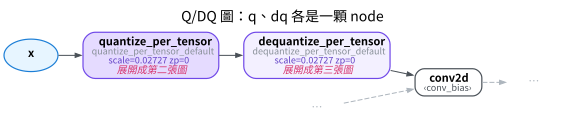

In [6]:
#| echo: false
ref = convert_pt2e(copy.deepcopy(prepared), use_reference_representation=True)
draw(qdq, focus=["x", "quantize_per_tensor_default", "dequantize_per_tensor_default", "conv2d"], hops=0, rankdir="LR",
     notes={"quantize_per_tensor_default": "展開成第二張圖", "dequantize_per_tensor_default": "展開成第三張圖"},
     title="Q/DQ 圖：q、dq 各是一顆 node")

換成 reference representation 之後，同一段變成 11 顆算術 node。分成兩張畫，node 底下是常數參數（scale、zp、dtype）：

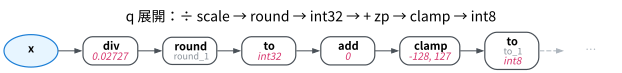

In [7]:
#| echo: false
def literal(node):
    args = [a for a in node.args[1:] if not hasattr(a, "op")]
    if args:
        return ", ".join(f"{a:.4g}" if isinstance(a, float) else str(a).replace("torch.", "") for a in args)
    return ""


chain, n = [], next(n for n in ref.graph.nodes if n.name == "conv2d").args[0]
while n.op == "call_function":
    chain.append(n)
    n = n.args[0]
chain.reverse()
split = next(i for i, c in enumerate(chain) if torch.int8 in c.args) + 1  # 轉成 int8 為止是 quantize
ref_notes = {c.name: literal(c) for c in chain}
draw(ref, focus=["x"] + [c.name for c in chain[:split]], hops=0, notes=ref_notes, rankdir="LR",
     title="q 展開：÷ scale → round → int32 → + zp → clamp → int8")

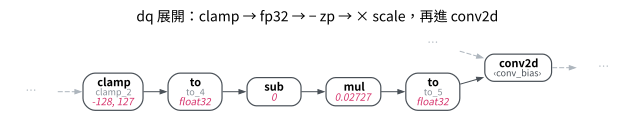

In [8]:
#| echo: false
draw(ref, focus=[c.name for c in chain[split:]] + ["conv2d"], hops=0, notes=ref_notes, rankdir="LR",
     title="dq 展開：clamp → fp32 → − zp → × scale，再進 conv2d")

conv2d 本身沒有變：它對不上 torchao 的 pattern（下面的表），仍然吃 fp32。被換掉的只有 q、dq。
這兩串算術就是下面兩條公式。scale $s$、zero point $z$、整數範圍 $[q_{min}, q_{max}]$：

$$
q = \operatorname{clamp}\big(\operatorname{round}(x / s) + z,\ q_{min},\ q_{max}\big) \tag{1}
$$

$$
\hat{x} = (q - z)\cdot s \tag{2}
$$

其中 $x/s$、round、$\times s$ 仍是浮點運算：這一步是「把公式寫出來」，不是換成 int8 kernel。

單元中間的運算怎麼處理，要看整個單元有沒有對上 torchao 寫好的 pattern：

| 情況 | 單元變成 | 在 torchao 0.18 上的例子（M07-2 B） |
|---|---|---|
| 沒對上 | int8 → dq 算術 → **fp32 運算** → q 算術 → int8 | 上面 conv_relu 的 conv |
| 對上 | int8 → **int32 累加／算術** → requantize → int8 | add + relu、per-tensor weight 的 linear |

PyTorch 官方把它定位為後端無關的參考格式（[PT2E 文件](https://docs.pytorch.org/ao/stable/pt2e_quantization/pt2e_quant_ptq.html)、[RFC-0019](https://github.com/pytorch/rfcs/blob/master/RFC-0019-Extending-PyTorch-Quantization-to-Custom-Backends.md)）：

- **適合**：明確寫出整數累加、bias 的 scale、requantize、clamp 的語意；當後端或編譯器作者實作 lowering 的共同參考；沒有目標硬體也能執行、檢查整數量化的邏輯。
- **不適合**：量最終的 latency（量到的只是 reference 算術的速度）；推測 oneDNN、XNNPACK、NPU 的實際效能；保證和特定硬體完全相同的 rounding／overflow 行為。

### lowering：pattern 對上了，才換成後端的 int8 op

lowering 在**編譯期**改圖，不是執行時才去問「有沒有 kernel」：

```text
decompose        把圖整理成 pattern 認得的形式（conv2d → convolution 等）
pattern match    跑後端事先註冊好的 pattern，例如 dq → conv → q
替換             對上的換成後端的 op（x86：onednn.qconv_pointwise）
其餘保留         沒註冊、沒對上的，原樣留在圖上
```

每個後端有自己的 lowering：

| 後端 | lowering 的入口 | 沒對上的單元 | 在哪一章 |
|---|---|---|---|
| x86（oneDNN） | `lower_pt2e_quantized_to_x86` | 原樣留在 fx 圖上，跑 fp32 | M07-2 C |
| XNNPACK | `to_edge_transform_and_lower(..., XnnpackPartitioner)` | 留在 delegate 外，由 ExecuTorch 的 portable kernel 跑 | M08 |
| ONNX Runtime | 匯出 QDQ ONNX，由 ORT 建 session 時做 QDQ fusion | 留在 fp32，前後各一次 int8 ↔ fp32 | M09 |
| 虛構的 VPU | 自己寫的 partitioner | 切回 CPU | M10 |

### Inductor：`torch.compile` 的編譯器

Inductor 是 `torch.compile` 預設的 backend。它對整張圖做 decompose、pattern matching、constant folding、逐元素運算的融合、layout 與記憶體規劃，最後在 CPU 上產生 C++ kernel；conv、matmul 這類運算則呼叫外部函式庫（oneDNN、BLAS、NNPACK 等）。
遇到 Q/DQ 圖時有兩種結果：

| 情況 | Inductor 做的事 |
|---|---|
| 有 int8 pattern，而且開了 freezing | dq → conv → q 換成 oneDNN 的 int8 conv（和 lowering 相同） |
| 沒有 int8 pattern | dq、q、relu 等逐元素運算融進它產生的 kernel；conv 仍呼叫 fp32 的 kernel |

### 三者的關係

x86 的 int8 pattern 不在 PyTorch 本體，而在 torchao（讀 torchao 0.18、torch 2.14 的原始碼）：

| 環節 | 在哪裡 | 做什麼 |
|---|---|---|
| pattern 本體 | torchao 的 `x86.py`（`inductor_passes/`） | 把 dq → conv → q 換成 oneDNN 的 int8 op（例如 `qconv_pointwise`） |
| 註冊 | import `x86_inductor_quantizer` 時 | 只在 mkldnn 可用時註冊，註冊到 Inductor 的 freezing pattern |
| 誰去跑（一） | torchao 的 `lower_pt2e_quantized_to_x86` | 直接呼叫 freezing pass，回傳改好的 fx 圖 |
| 誰去跑（二） | `torch.compile` | 只在 Inductor 的 `freezing` 設定開啟、且在 `no_grad` 下才跑；`freezing` 預設關（torch 的 `compile_fx.py`） |


## 比較後端之前的規矩

M07-1 之後，每一章都會拿某個實作的結果和 Q/DQ 圖或 fp32 模型比。比之前先講好四件事。

### fp32 的數值底線

比較兩種實作（Q/DQ 圖 vs reference、eager vs lowering、PyTorch vs ONNX Runtime）時，差異不全是量化造成的。完全不量化的 fp32 模型，只要 CPU 換了 conv 的實作（例如 batch size 不同就改走 NNPACK），輸出就會差 1e-5～1e-4。
這個量級就是**數值底線**：小於它的差，不是量化或 lowering 的錯。M07-1 量它，並用 `torch.backends` 的開關在任何機器上重現。

### 後端和 Q/DQ 圖不保證逐位元相同

Q/DQ 圖用 fp32 模擬量化，後端的整數 kernel 是真的用整數算，捨入的位置不同。
另一個已知來源是 bias：Q/DQ 圖的 bias 是 fp32，XNNPACK 在 lowering 時把它量化成 int32，scale = $s_x \cdot s_w$（executorch 1.5.0 的 `quant_params.py`，`from_bias`），ORT 的 `ORT_ENABLE_BASIC` 等級也做同樣的事（M09-2）。

所以比較後端時只看最後的輸出：

| 指標 | 回答什麼 |
|---|---|
| 對 fp32 的 SQNR、accuracy | 精度有沒有變差 |
| 輸出逐位元相同的比例 | 和 Q/DQ 圖有多接近 |
| argmax 一致率 | 分類結果有沒有變 |
| 最大差幾個輸出 LSB | 差異是不是只是捨入 |

### 速度的基準：同一個 runtime 的 fp32

Q/DQ 圖本身比 eager 還慢（多了 q、dq 的 fp32 運算）；fp32 模型換到另一個 runtime 也可能快很多。所以 int8 的收益，要和同一個 runtime 裡的 fp32 模型比（M08-4）。
M07 的三種處理都沒有產生 int8 kernel，所以這一章不量 latency。

### 部署到裝置端，常要 static shape

本專案的 `export_module()`（`common/pt2e.py` 裡的包裝，不是 torch 的 API）預設開動態 batch，因為校準時要餵不同的 batch size。
ExecuTorch 的 `.pte` 依匯出時的 shape 排好記憶體，M08 因此改用 `export_module(..., dynamic_batch=False)`；ONNX 匯出時要用 `dynamic_shapes` 再指定一次（M09-1）；M10 的虛構 VPU 只吃 static shape，用 `validate()` 擋下動態 batch。

## 平台說明

這篇與本章 notebook 存的輸出，是在 macOS arm64、torch 2.14.0、torchao 0.18、executorch 1.5.0、onnxruntime 1.30.0、沒有 mkldnn 的環境跑的：x86 的 int8 pattern 沒有註冊，M07 的三種處理都沒有把 conv 變成 int8 kernel。
在你的機器上執行時，ExecuTorch 的 backend 清單、表格下的說明會依實測印出。x86（有 mkldnn）上 lowering 與 `torch.compile` 的實際結果，這裡沒有驗證。

## 小結與地圖

- 後端分成三層：推論框架讀部署檔、分派子圖；硬體擴充單位是轉接頭；kernel 函式庫負責算。同一個名字可能出現在好幾層。
- 三條路線都從同一張 Q/DQ 圖出發，差在橋接步驟，以及「誰、在哪一步」把 `dq → op → q` 換成 int8 kernel。
- Quantizer 要配合後端：量化位置與 qspec 是照後端的 kernel 設計的，不配時單元會留在 fallback。
- 在 PyTorch 裡，reference representation 寫出量化的數學，對上 pattern 的單元才改成整數；lowering 把對上的 pattern 換成後端的 int8 op；Inductor 編譯整張圖，開 freezing 且有 pattern 時也會換成 int8 kernel。
- 比較後端之前，先知道 fp32 的底線、只比最後輸出、速度和同一個 runtime 的 fp32 比。

本章的 notebook：

| notebook | 回答的問題 |
|---|---|
| [M07-1 fp32 的數值底線](01_fp32_numeric_floor.ipynb) | 只換 kernel 時 fp32 差多少；profiler 看 kernel；用 `torch.backends` 手動切換 |
| [M07-2 三種處理](02_representation_and_lowering.ipynb) | 同一張 Q/DQ 圖經 reference representation、x86 lowering、`torch.compile` 各變成什麼 op |

接下來的三章：

| 章節 | 路線 | 回答的問題 |
|---|---|---|
| M08 XNNPACK／ExecuTorch | A | 兩份 `XNNPACKQuantizer` 差在哪；Q/DQ 圖怎麼變成 `.pte`；不支援的 op 怎麼切；int8 快多少 |
| M09 ONNX Runtime | B | Q/DQ 圖怎麼匯出成 QDQ ONNX；ORT 的最佳化等級各改了什麼；哪些 op 會換成 int8 |
| M10 自訂後端 | 自訂 | 把硬體約束寫成 Quantizer；檢查 Q/DQ 圖是否合規；不支援的 op 切回 CPU |

這篇刻意跳過的：後端真正的 int8 kernel 和 Q/DQ 圖差多少（M08、M09）；OpenVINO 的完整流程（本專案只做過轉換試作）。

## 參考資料

- PyTorch 官方教學：[PyTorch 2 Export Post Training Quantization](https://docs.pytorch.org/ao/stable/pt2e_quantization/pt2e_quant_ptq.html)（reference representation 的定位）
- [RFC-0019：Extending PyTorch Quantization to Custom Backends](https://github.com/pytorch/rfcs/blob/master/RFC-0019-Extending-PyTorch-Quantization-to-Custom-Backends.md)
- torchao 0.18 原始碼：[`reference_representation_rewrite.py`](https://github.com/pytorch/ao/blob/v0.18.0/torchao/quantization/pt2e/reference_representation_rewrite.py)、[`inductor_passes/x86.py`](https://github.com/pytorch/ao/blob/v0.18.0/torchao/quantization/pt2e/inductor_passes/x86.py)、[`lowering.py`](https://github.com/pytorch/ao/blob/v0.18.0/torchao/quantization/pt2e/lowering.py)
- torch 2.14 原始碼：[`_inductor/compile_fx.py`](https://github.com/pytorch/pytorch/blob/v2.14.0/torch/_inductor/compile_fx.py)（freezing 何時執行）；文件：[torch.compiler](https://docs.pytorch.org/docs/2.14/torch.compiler.html)
- ExecuTorch：[Backends 總覽](https://docs.pytorch.org/executorch/stable/backends-overview.html)；1.5.0 原始碼的 [`backends/`](https://github.com/pytorch/executorch/tree/v1.5.0/backends)
- ONNX Runtime：[Execution Providers](https://onnxruntime.ai/docs/execution-providers/)；[v1.30.0 原始碼](https://github.com/microsoft/onnxruntime/tree/v1.30.0)
- [XNNPACK](https://github.com/google/XNNPACK)；OpenVINO 文件：[Model Preparation](https://docs.openvino.ai/2026/openvino-workflow/model-preparation.html)（`ov.convert_model`）
- [Quantization 的那些事](https://bobondemon.github.io/2020/10/03/Quantization-%E7%9A%84%E9%82%A3%E4%BA%9B%E4%BA%8B/#%E7%B4%94%E7%94%A8-Integer-%E9%81%8B%E7%AE%97)：從 affine 量化公式推出純整數運算，包含只用整數乘法與位移做 requantize（fractional multiplication），對應 reference representation 裡的整數算術